<a href="https://colab.research.google.com/github/amit809070/Machine-Learning-Lab-Assignments---M-tech-CSE/blob/main/Lab_03_Logistic%20Regression_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 2: Logistic Regression and Perceptron         
Objective:To implement Logistic Regression and the Perceptron learning algorithm for binary classification and compare their performance.

In [1]:
# Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load Breast Cancer Dataset

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset loaded successfully.")
print("Dataset shape:", X.shape)

print("\nNumber of features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nTarget classes:")
print(data.target_names)

print("\nFirst 5 records:")
print(X[:5])

print("\nFirst 5 target values:")
print(y[:5])

Dataset loaded successfully.
Dataset shape: (569, 30)

Number of features: 30
Number of samples: 569

Target classes:
['malignant' 'benign']

First 5 records:
[[1.799e+01 1.038e+01 1.228e+02 1.001e+03 1.184e-01 2.776e-01 3.001e-01
  1.471e-01 2.419e-01 7.871e-02 1.095e+00 9.053e-01 8.589e+00 1.534e+02
  6.399e-03 4.904e-02 5.373e-02 1.587e-02 3.003e-02 6.193e-03 2.538e+01
  1.733e+01 1.846e+02 2.019e+03 1.622e-01 6.656e-01 7.119e-01 2.654e-01
  4.601e-01 1.189e-01]
 [2.057e+01 1.777e+01 1.329e+02 1.326e+03 8.474e-02 7.864e-02 8.690e-02
  7.017e-02 1.812e-01 5.667e-02 5.435e-01 7.339e-01 3.398e+00 7.408e+01
  5.225e-03 1.308e-02 1.860e-02 1.340e-02 1.389e-02 3.532e-03 2.499e+01
  2.341e+01 1.588e+02 1.956e+03 1.238e-01 1.866e-01 2.416e-01 1.860e-01
  2.750e-01 8.902e-02]
 [1.969e+01 2.125e+01 1.300e+02 1.203e+03 1.096e-01 1.599e-01 1.974e-01
  1.279e-01 2.069e-01 5.999e-02 7.456e-01 7.869e-01 4.585e+00 9.403e+01
  6.150e-03 4.006e-02 3.832e-02 2.058e-02 2.250e-02 4.571e-03 2.357e+01
  2

In [3]:
# Convert Dataset into DataFrame

df = pd.DataFrame(X, columns=data.feature_names)

# Add target column
df["Target"] = y

print("----- DATASET -----")
display(df.head())

print("\n----- DATASET INFORMATION -----")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n----- TARGET DISTRIBUTION -----")
print(df["Target"].value_counts())

----- DATASET -----


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



----- DATASET INFORMATION -----
Rows: 569
Columns: 31

----- TARGET DISTRIBUTION -----
Target
1    357
0    212
Name: count, dtype: int64


In [4]:
# Separate Input and Output

X = df.drop("Target", axis=1).values
y = df["Target"].values

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (569, 30)
Target shape: (569,)


In [5]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [6]:
 # Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [7]:
# Logistic Regression using Gradient Descent

# Sigmoid Function

def sigmoid(z):
    """
    Sigmoid activation function.
    Converts any value into a value between 0 and 1.
    """

    # Prevent overflow
    z = np.clip(z, -500, 500)

    return 1 / (1 + np.exp(-z))


# Test sigmoid function
print("Sigmoid(0) =", sigmoid(0))
print("Sigmoid(1) =", sigmoid(1))
print("Sigmoid(-1) =", sigmoid(-1))

Sigmoid(0) = 0.5
Sigmoid(1) = 0.7310585786300049
Sigmoid(-1) = 0.2689414213699951


In [8]:
# Logistic Regression From Scratch
# Using Gradient Descent

class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, epochs=2000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.loss_history = []

    def fit(self, X, y):

        # Number of samples and features
        n_samples, n_features = X.shape

        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0

        for epoch in range(self.epochs):

            # Linear equation
            linear_output = np.dot(X, self.weights) + self.bias

            # Sigmoid activation
            y_predicted = sigmoid(linear_output)

            # Binary Cross Entropy Loss
            epsilon = 1e-15

            loss = -np.mean(
                y * np.log(y_predicted + epsilon) +
                (1 - y) * np.log(1 - y_predicted + epsilon)
            )

            self.loss_history.append(loss)

            # Calculate gradients
            dw = (1 / n_samples) * np.dot(
                X.T,
                (y_predicted - y)
            )

            db = (1 / n_samples) * np.sum(
                y_predicted - y
            )

            # Update weights
            self.weights -= self.learning_rate * dw

            # Update bias
            self.bias -= self.learning_rate * db

        return self

    def predict_probability(self, X):

        linear_output = np.dot(X, self.weights) + self.bias

        return sigmoid(linear_output)

    def predict(self, X):

        probabilities = self.predict_probability(X)

        return (probabilities >= 0.5).astype(int)

In [9]:
# Train Logistic Regression Model

logistic_model = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=2000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [10]:
# CELL 10: Logistic Regression Prediction

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("First 20 actual values:")
print(y_test[:20])

print("\nFirst 20 predicted values:")
print(y_pred_logistic[:20])

First 20 actual values:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1]

First 20 predicted values:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1]


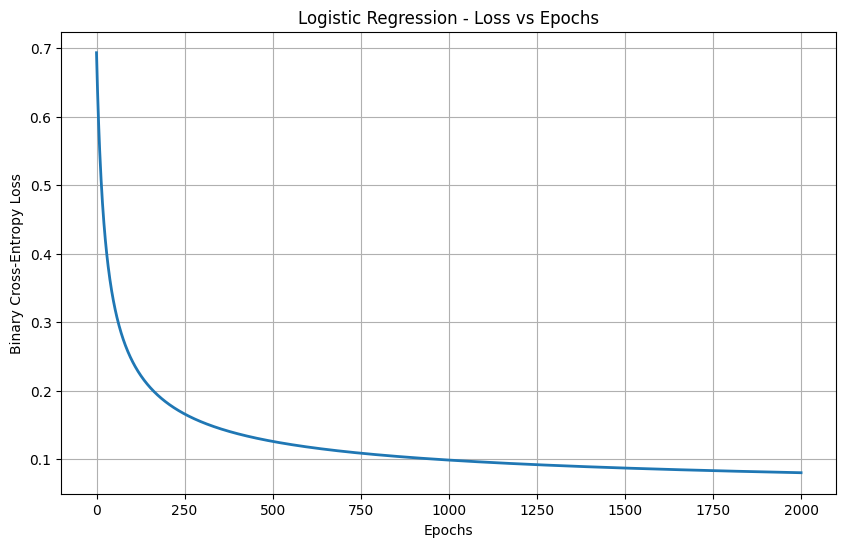

In [11]:
# Plot Logistic Regression Loss

plt.figure(figsize=(10, 6))

plt.plot(
    logistic_model.loss_history,
    linewidth=2
)

plt.title("Logistic Regression - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

In [12]:
# Perceptron From Scratch

class PerceptronScratch:

    def __init__(self, learning_rate=0.01, epochs=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.errors_history = []

    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Initialize weights
        self.weights = np.zeros(n_features)
        self.bias = 0

        # Convert labels:
        # 0 -> -1
        # 1 -> +1
        y_perceptron = np.where(y == 0, -1, 1)

        for epoch in range(self.epochs):

            errors = 0

            for xi, target in zip(X, y_perceptron):

                # Calculate activation
                activation = np.dot(xi, self.weights) + self.bias

                # Prediction
                prediction = 1 if activation >= 0 else -1

                # Update if prediction is wrong
                if prediction != target:

                    self.weights += (
                        self.learning_rate * target * xi
                    )

                    self.bias += (
                        self.learning_rate * target
                    )

                    errors += 1

            self.errors_history.append(errors)

        return self

    def predict(self, X):

        linear_output = (
            np.dot(X, self.weights) + self.bias
        )

        return np.where(
            linear_output >= 0,
            1,
            0
        )

In [13]:
# Train Perceptron

perceptron_model = PerceptronScratch(
    learning_rate=0.01,
    epochs=100
)

perceptron_model.fit(
    X_train_scaled,
    y_train
)

print("Perceptron training completed.")

Perceptron training completed.


In [14]:
# Perceptron Prediction

y_pred_perceptron = perceptron_model.predict(
    X_test_scaled
)

print("First 20 actual values:")
print(y_test[:20])

print("\nFirst 20 predicted values:")
print(y_pred_perceptron[:20])

First 20 actual values:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1]

First 20 predicted values:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1]


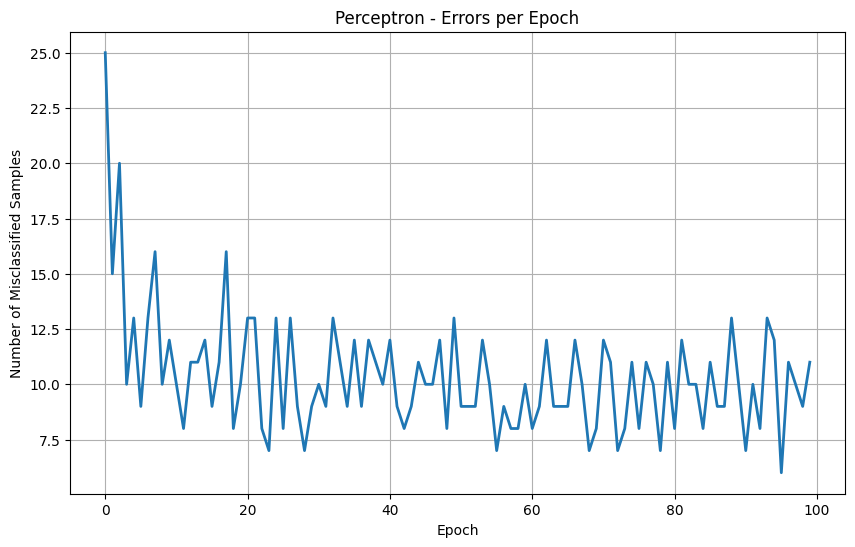

In [15]:
# Plot Perceptron Errors

plt.figure(figsize=(10, 6))

plt.plot(
    perceptron_model.errors_history,
    linewidth=2
)

plt.title("Perceptron - Errors per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Number of Misclassified Samples")

plt.grid(True)
plt.show()

In [34]:
# Evaluation Function

def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    print("\n==========================================")
    print(model_name)
    print("==========================================")

    print("Accuracy  :", round(accuracy, 4))
    print("Precision :", round(precision, 4))
    print("Recall    :", round(recall, 4))
    print("F1-Score  :", round(f1, 4))

    return accuracy, precision, recall, f1

In [17]:
# Evaluate Logistic Regression

logistic_metrics = evaluate_model(
    "LOGISTIC REGRESSION",
    y_test,
    y_pred_logistic
)


LOGISTIC REGRESSION
Accuracy  : 0.9737
Precision : 0.9859
Recall    : 0.9722
F1-Score  : 0.979


In [18]:
# Evaluate Perceptron

perceptron_metrics = evaluate_model(
    "PERCEPTRON",
    y_test,
    y_pred_perceptron
)


PERCEPTRON
Accuracy  : 0.9474
Precision : 0.9583
Recall    : 0.9583
F1-Score  : 0.9583


In [19]:
#  Model Comparison Table

comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Logistic Regression": [
        logistic_metrics[0],
        logistic_metrics[1],
        logistic_metrics[2],
        logistic_metrics[3]
    ],

    "Perceptron": [
        perceptron_metrics[0],
        perceptron_metrics[1],
        perceptron_metrics[2],
        perceptron_metrics[3]
    ]
})

print("----- MODEL PERFORMANCE COMPARISON -----")

display(
    comparison.style.format({
        "Logistic Regression": "{:.4f}",
        "Perceptron": "{:.4f}"
    })
)

----- MODEL PERFORMANCE COMPARISON -----


,Metric,Logistic Regression,Perceptron
0,Accuracy,0.9737,0.9474
1,Precision,0.9859,0.9583
2,Recall,0.9722,0.9583
3,F1-Score,0.9790,0.9583


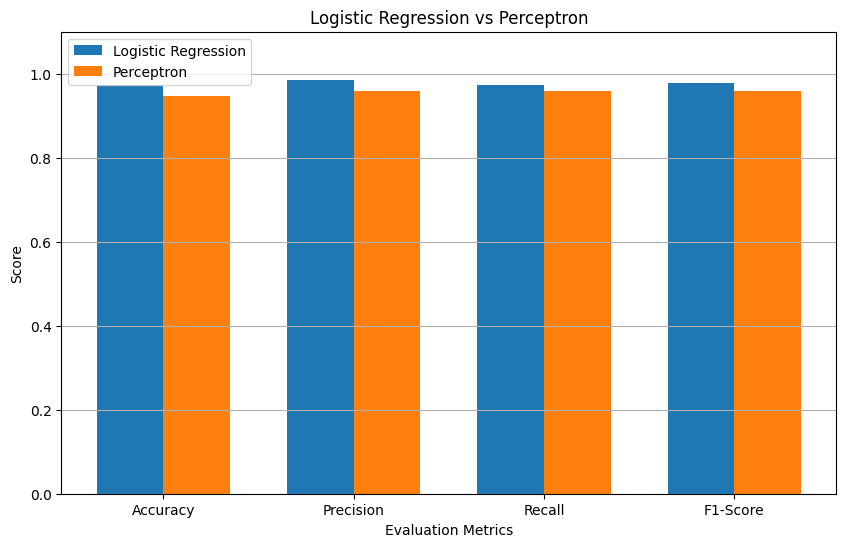

In [20]:
#  Performance Comparison Graph

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

logistic_values = [
    logistic_metrics[0],
    logistic_metrics[1],
    logistic_metrics[2],
    logistic_metrics[3]
]

perceptron_values = [
    perceptron_metrics[0],
    perceptron_metrics[1],
    perceptron_metrics[2],
    perceptron_metrics[3]
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    logistic_values,
    width,
    label="Logistic Regression"
)

plt.bar(
    x + width/2,
    perceptron_values,
    width,
    label="Perceptron"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("Logistic Regression vs Perceptron")

plt.ylim(0, 1.1)

plt.legend()
plt.grid(axis="y")

plt.show()

In [21]:
# Classification Report

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")


print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=data.target_names,
        zero_division=0
    )
)


print("PERCEPTRON CLASSIFICATION REPORT")


print(
    classification_report(
        y_test,
        y_pred_perceptron,
        target_names=data.target_names,
        zero_division=0
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

PERCEPTRON CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



Logistic Regression Confusion Matrix:
[[41  1]
 [ 2 70]]


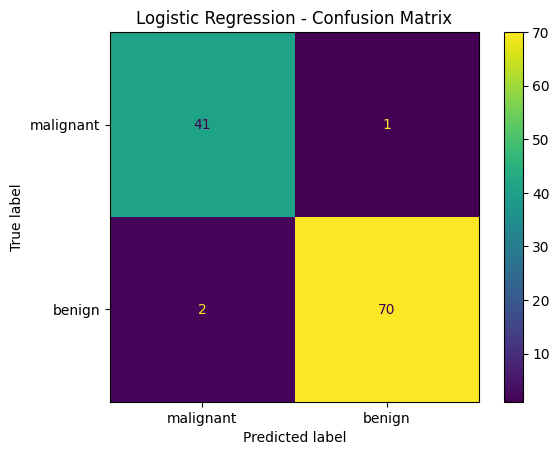

In [22]:
# Logistic Regression Confusion Matrix

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=data.target_names
)

disp.plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

Perceptron Confusion Matrix:
[[39  3]
 [ 3 69]]


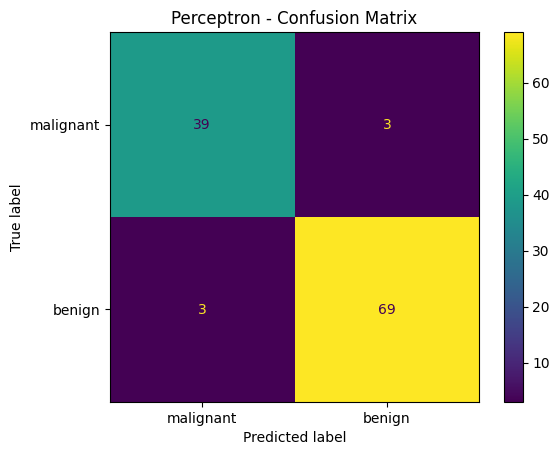

In [23]:
#  Perceptron Confusion Matrix

cm_perceptron = confusion_matrix(
    y_test,
    y_pred_perceptron
)

print("Perceptron Confusion Matrix:")
print(cm_perceptron)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_perceptron,
    display_labels=data.target_names
)

disp.plot()

plt.title("Perceptron - Confusion Matrix")
plt.show()

In [24]:
# Select 2 Features for Decision Boundary

feature1 = "mean radius"
feature2 = "mean texture"

feature_indices = [
    list(data.feature_names).index(feature1),
    list(data.feature_names).index(feature2)
]

X_two = df[
    [feature1, feature2]
].values

y_two = df["Target"].values

print("Selected Features:")
print("1.", feature1)
print("2.", feature2)

print("\nShape of selected dataset:")
print(X_two.shape)

Selected Features:
1. mean radius
2. mean texture

Shape of selected dataset:
(569, 2)


In [25]:
# Train-Test Split for 2 Features

X_two_train, X_two_test, y_two_train, y_two_test = train_test_split(
    X_two,
    y_two,
    test_size=0.20,
    random_state=42,
    stratify=y_two
)

# Scale 2-feature data
scaler_two = StandardScaler()

X_two_train_scaled = scaler_two.fit_transform(
    X_two_train
)

X_two_test_scaled = scaler_two.transform(
    X_two_test
)

print("2-feature training data:", X_two_train_scaled.shape)
print("2-feature testing data:", X_two_test_scaled.shape)

2-feature training data: (455, 2)
2-feature testing data: (114, 2)


In [26]:
# Train Logistic Regression on 2 Features

logistic_two = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=2000
)

logistic_two.fit(
    X_two_train_scaled,
    y_two_train
)

print("2-feature Logistic Regression trained.")

2-feature Logistic Regression trained.


In [27]:
# Train Perceptron on 2 Features

perceptron_two = PerceptronScratch(
    learning_rate=0.01,
    epochs=100
)

perceptron_two.fit(
    X_two_train_scaled,
    y_two_train
)

print("2-feature Perceptron trained.")

2-feature Perceptron trained.


In [28]:
# Logistic Regression Decision Boundary

def plot_decision_boundary(
    model,
    X,
    y,
    feature_names,
    title
):

    # Find minimum and maximum values
    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1

    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1

    # Create grid
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 500),
        np.linspace(y_min, y_max, 500)
    )

    # Convert grid into points
    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ]

    # Predict classes
    predictions = model.predict(grid)

    predictions = predictions.reshape(
        xx.shape
    )

    # Plot decision regions
    plt.figure(figsize=(10, 7))

    plt.contourf(
        xx,
        yy,
        predictions,
        alpha=0.25
    )

    # Plot actual data points
    scatter = plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolor="black",
        s=45
    )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])

    plt.title(title)

    plt.colorbar(
        scatter,
        label="Class"
    )

    plt.grid(True)

    plt.show()

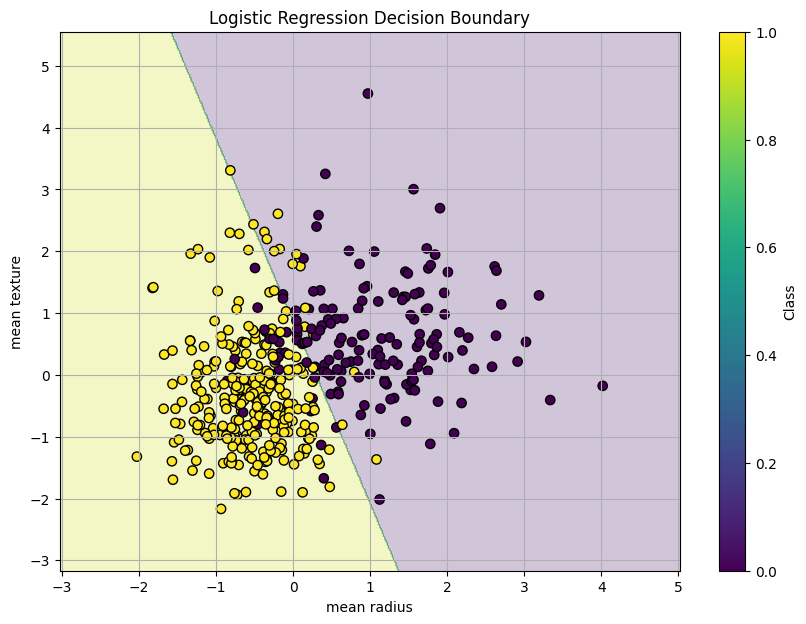

In [29]:
# Plot Logistic Regression Decision Boundary

plot_decision_boundary(
    logistic_two,
    X_two_train_scaled,
    y_two_train,
    [feature1, feature2],
    "Logistic Regression Decision Boundary"
)

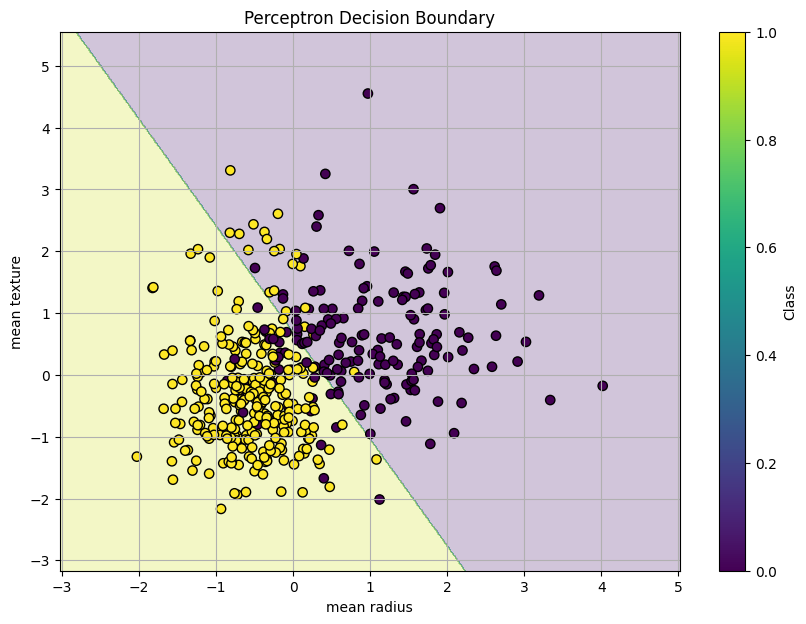

In [30]:
# Plot Perceptron Decision Boundary

plot_decision_boundary(
    perceptron_two,
    X_two_train_scaled,
    y_two_train,
    [feature1, feature2],
    "Perceptron Decision Boundary"
)

In [31]:
# Compare Both Decision Boundaries

def plot_two_boundaries(
    logistic_model,
    perceptron_model,
    X,
    y,
    feature_names
):

    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1

    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 500),
        np.linspace(y_min, y_max, 500)
    )

    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ]

    logistic_pred = logistic_model.predict(grid)
    perceptron_pred = perceptron_model.predict(grid)

    logistic_pred = logistic_pred.reshape(xx.shape)
    perceptron_pred = perceptron_pred.reshape(xx.shape)

    # Logistic Regression

    plt.figure(figsize=(10, 7))

    plt.contourf(
        xx,
        yy,
        logistic_pred,
        alpha=0.25
    )

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolor="black",
        s=45
    )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])

    plt.title(
        "Logistic Regression - 2 Feature Decision Boundary"
    )

    plt.grid(True)

    plt.show()

    # Perceptron


    plt.figure(figsize=(10, 7))

    plt.contourf(
        xx,
        yy,
        perceptron_pred,
        alpha=0.25
    )

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolor="black",
        s=45
    )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])

    plt.title(
        "Perceptron - 2 Feature Decision Boundary"
    )

    plt.grid(True)

    plt.show()

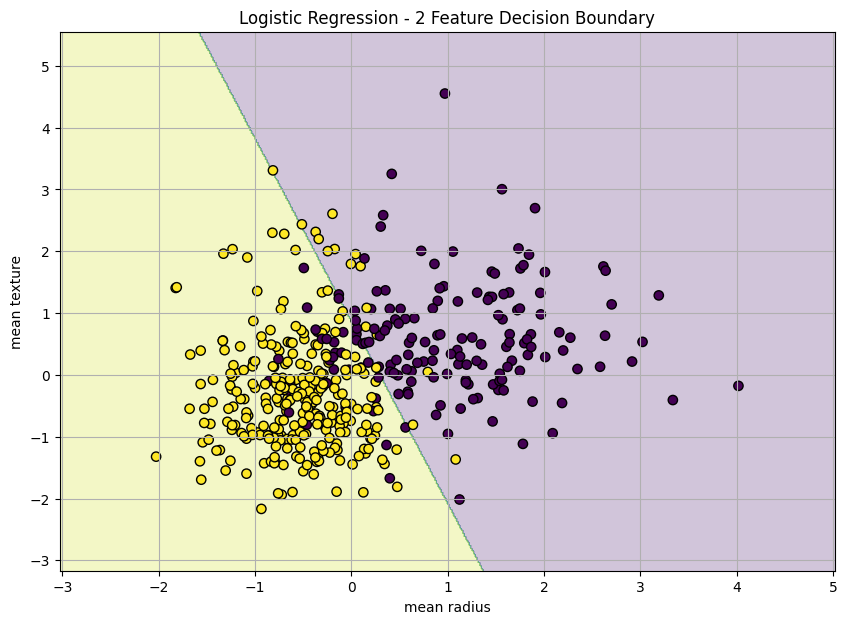

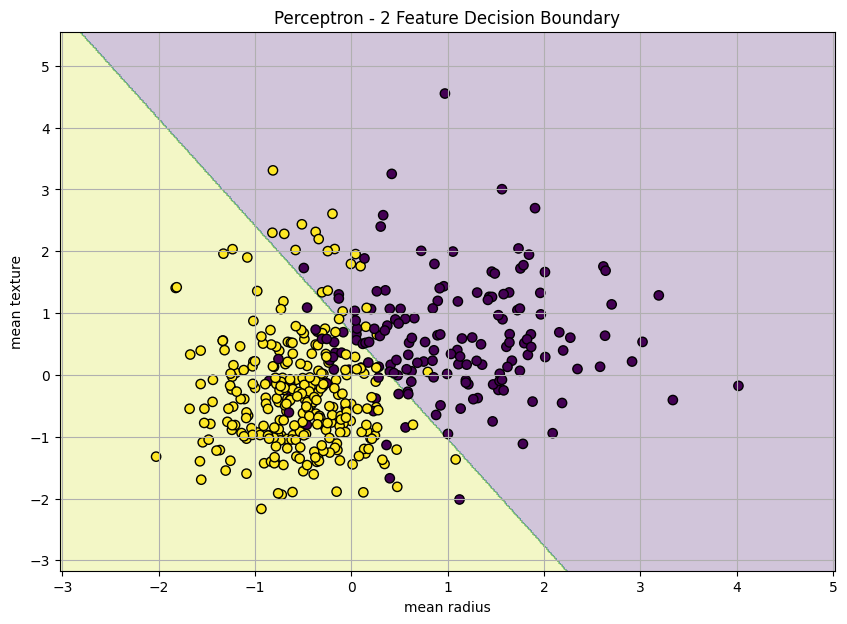

In [32]:
# Display Both Decision Boundaries

plot_two_boundaries(
    logistic_two,
    perceptron_two,
    X_two_train_scaled,
    y_two_train,
    [feature1, feature2]
)

In [33]:
# FINAL EXPERIMENT RESULT

print("=" * 60)
print("EXPERIMENT 2 COMPLETED SUCCESSFULLY")
print("=" * 60)

print("\nTasks Completed:")
print("1. Breast Cancer dataset loaded.")
print("2. Logistic Regression implemented from scratch.")
print("3. Gradient Descent with Sigmoid activation implemented.")
print("4. Perceptron learning rule implemented from scratch.")
print("5. Accuracy calculated.")
print("6. Precision calculated.")
print("7. Recall calculated.")
print("8. F1-Score calculated.")
print("9. Logistic Regression loss graph plotted.")
print("10. Perceptron error graph plotted.")
print("11. Performance comparison graph plotted.")
print("12. Confusion matrices generated.")
print("13. 2-feature decision boundary plotted.")
print("14. Logistic Regression and Perceptron compared.")

print("\n" + "=" * 60)
print("FINAL PERFORMANCE COMPARISON")
print("=" * 60)

display(
    comparison.style.format({
        "Logistic Regression": "{:.4f}",
        "Perceptron": "{:.4f}"
    })
)

EXPERIMENT 2 COMPLETED SUCCESSFULLY

Tasks Completed:
1. Breast Cancer dataset loaded.
2. Logistic Regression implemented from scratch.
3. Gradient Descent with Sigmoid activation implemented.
4. Perceptron learning rule implemented from scratch.
5. Accuracy calculated.
6. Precision calculated.
7. Recall calculated.
8. F1-Score calculated.
9. Logistic Regression loss graph plotted.
10. Perceptron error graph plotted.
11. Performance comparison graph plotted.
12. Confusion matrices generated.
13. 2-feature decision boundary plotted.
14. Logistic Regression and Perceptron compared.

FINAL PERFORMANCE COMPARISON


,Metric,Logistic Regression,Perceptron
0,Accuracy,0.9737,0.9474
1,Precision,0.9859,0.9583
2,Recall,0.9722,0.9583
3,F1-Score,0.9790,0.9583
